# Headline figure
One graph for a non-specialist, used in both the video and the article. Run notebook 01 first.

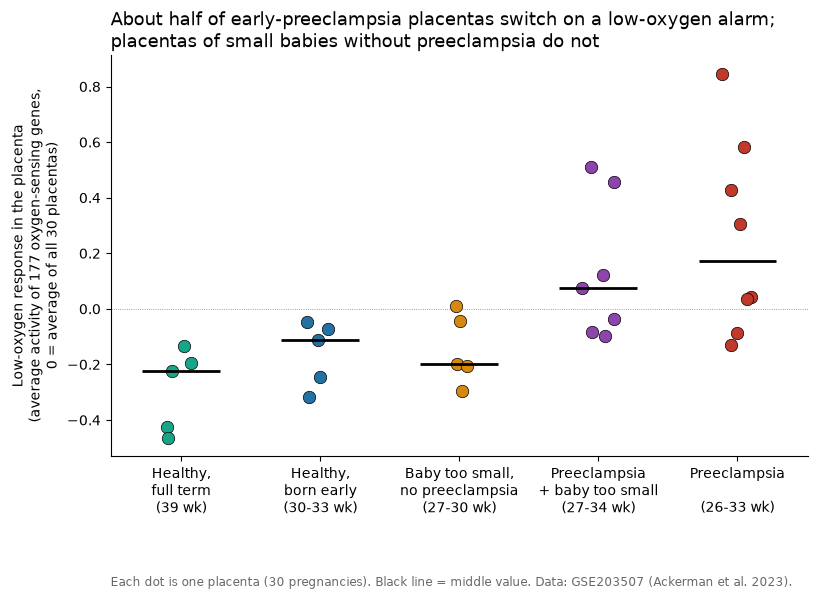

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = Path("../figures"); RES_DIR = Path("results")
s = pd.read_csv(RES_DIR / "pathway_scores.csv", index_col=0)
order = [("TB", "Healthy,\nfull term\n(39 wk)", "#17a589"),
         ("iPTB", "Healthy,\nborn early\n(30-33 wk)", "#2471a3"),
         ("FGR", "Baby too small,\nno preeclampsia\n(27-30 wk)", "#d68910"),
         ("EOPE+FGR", "Preeclampsia\n+ baby too small\n(27-34 wk)", "#8e44ad"),
         ("EOPE", "Preeclampsia\n\n(26-33 wk)", "#c0392b")]
rng = np.random.default_rng(3)
fig, ax = plt.subplots(figsize=(9, 5.2))
for i, (g, lab, col) in enumerate(order):
    v = s.loc[s.group == g, "HALLMARK_HYPOXIA"]
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=80, c=col, edgecolor="k", lw=0.5, zorder=3)
    ax.hlines(v.median(), i - 0.28, i + 0.28, color="k", lw=2, zorder=4)
ax.axhline(0, c="grey", lw=0.6, ls=":")
ax.set_xticks(range(len(order))); ax.set_xticklabels([o[1] for o in order], fontsize=10)
ax.set_ylabel("Low-oxygen response in the placenta\n(average activity of 177 oxygen-sensing genes,\n0 = average of all 30 placentas)", fontsize=10)
ax.set_title("About half of early-preeclampsia placentas switch on a low-oxygen alarm;\nplacentas of small babies without preeclampsia do not",
             fontsize=13, loc="left")
ax.text(0, -0.30, "Each dot is one placenta (30 pregnancies). Black line = middle value. Data: GSE203507 (Ackerman et al. 2023).",
        transform=ax.transAxes, fontsize=8.5, color="dimgrey", va="top")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(FIG_DIR / "headline.png", dpi=300, bbox_inches="tight"); plt.show()